In [2]:
from collections import defaultdict
from pathlib import Path

import pandas as pd
from acteval.plot.frequency import plot_agg_acts
from acteval.plot.times import joint_time_distributions_plot
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from plots import plot_b

In [3]:
cmap = {
    "home": (0.5529411764705883, 0.8274509803921568, 0.7803921568627451),
    "other": (1.0, 1.0, 0.7019607843137254),
    "shop": (0.7450980392156863, 0.7294117647058823, 0.8549019607843137),
    "work": (0.984313725490196, 0.5019607843137255, 0.4470588235294118),
    "escort": (0.5019607843137255, 0.6941176470588235, 0.8274509803921568),
    "visit": (0.9921568627450981, 0.7058823529411765, 0.3843137254901961),
    "education": (0.7019607843137254, 0.8705882352941177, 0.4117647058823529),
    "medical": (0.9882352941176471, 0.803921568627451, 0.8980392156862745),
    "travel": (0.8509803921568627, 0.8509803921568627, 0.8509803921568627),
    "leisure": (0.996078431372549, 0.8509803921568627, 0.6509803921568628),
}


def latest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[-1]


def earliest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[0]


def iter_models(path: Path):
    for dir in path.iterdir():

        if dir.is_dir():

            yield latest(dir)


def find_nth(path: Path, n=0):

    ranks = (
        pd.read_csv(path / "domain_distances.csv")
        .drop(columns=["domain", "observed", "mean", "std"], errors="ignore")
        .rank(axis=1, method="min")
        .sum(axis=0)
    )
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def best_quality(path: Path, n=0):

    data = pd.read_csv(path / "domain_distances.csv")
    data = data[data.domain == "sample quality"].drop(
        columns=["domain", "observed", "mean", "std"], errors="ignore"
    )
    ranks = data.rank(axis=1, method="min").sum(axis=0)
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def load_attributes(path: Path, default=None):
    if (path / "synthetic_attributes.csv").exists():
        print(f"Loading synthetic attributes from {path}")
        return pd.read_csv(path / "synthetic_attributes.csv")
    if (path / "synthetic_labels.csv").exists():
        print(f"Loading synthetic labels from {path}")
        return pd.read_csv(path / "synthetic_labels.csv")
    print(f"Failed to find attributes at {path}")
    return default


def split_on(schedules, attributes, by="work_status", remove_unknown=False):
    splits = attributes.groupby(by)
    split = {
        k: schedules.loc[schedules.pid.isin(list(v.pid))]
        for k, v in splits
        if k != "unknown" or not remove_unknown
    }
    print(
        f"Split schedules into {len(split)} groups by {by}: {list(split.keys())}"
    )
    return split


def styler(df, vmin=-1, vmax=1):
    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24", "23-24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None

    styled = df.style.background_gradient(
        cmap="RdYlGn", vmin=vmin, vmax=vmax
    ).format("{:.1%}", na_rep="")

    return styled

In [18]:
training_data_route = Path("../../tmp/foundation/world")

training_schedules = {}
training_attributes = {}

counts = defaultdict(list)
for scope in [
    "training",
    "london",
    "uk",
    "dutch",
    "us",
    "chicago",
    "queensland",
    "victoria",
    "kr",
]:
    schedules_path = Path(training_data_route / f"{scope}_activities.csv")
    attributes_path = Path(training_data_route / f"{scope}_attributes.csv")
    training_schedules[f"{scope}"] = pd.read_csv(schedules_path)
    training_attributes[f"{scope}"] = pd.read_csv(attributes_path)

/tmp/ipykernel_187875/4206428320.py:21: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{scope}"] = pd.read_csv(attributes_path)
/tmp/ipykernel_187875/4206428320.py:21: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{scope}"] = pd.read_csv(attributes_path)


In [19]:
sizes = {}
for name, atts in training_attributes.items():
    print(name, atts.pid.nunique(), len(atts))
    sizes[name] = len(atts)

training 2376675 2376675
london 27432 27432
uk 200755 200755
dutch 117902 117902
us 15309 15309
chicago 25626 25626
queensland 14749 14749
victoria 16515 16515
kr 120100 120100


In [10]:
def freq_plotter(
    target_schedules,
    target_attributes,
    schedules,
    attributes,
    by=None,
    filter=None,
    names=None,
):

    acts = set()
    for sched in schedules.values():
        acts.update(sched.act.unique())

    act_order = target_schedules.act.value_counts().index.to_list()
    class_map = {n: i for i, n in enumerate(act_order)}

    if by is None:
        by = "employment"
        FILTER = ["student", "employed", "unemployed", "retired", "unknown"]
        NAMES = ["Student", "Employed", "Unemployed", "Retired", "Unknown"]
    else:
        if filter is None:
            FILTER = set()
            for atts in attributes.values():
                FILTER.update(atts[by].unique().tolist())
            FILTER = list(FILTER)
        else:
            FILTER = filter
        if names is None:
            NAMES = [str(f).title() for f in FILTER]

    h = len(schedules)
    w = len(FILTER)
    fig, axes = plt.subplots(
        h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
    )

    for i, (name, scheds) in enumerate(schedules.items()):

        splits = split_on(scheds, attributes[name], by=by)

        for j, f in enumerate(FILTER):
            axes[0, j].set_title(NAMES[j], fontsize=12)
            selected = splits.get(f)
            if selected is None:
                axes[i, j].axis("off")
                continue
            ax = plot_agg_acts(
                "",
                selected,
                class_map=class_map,
                ax=axes[i, j],
                legend=False,
                color=cmap,
            )
            ax.set_title(None)
            ax.set_ylabel(None)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_xticks([])

            axes[-1, j].set_xticks(
                [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
                labels=[
                    "",
                    "04:00",
                    "08:00",
                    "12:00",
                    "16:00",
                    "20:00",
                    "24:00",
                ],
                rotation=90,
                fontsize=8,
            )

        axes[0, -2].set_title("Combined", fontsize=12)
        ax = plot_agg_acts(
            "",
            scheds,
            class_map=class_map,
            ax=axes[i, -2],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, -2].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

        axes[i, 0].set_ylabel(name, fontsize=12)
        axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        axes[i, 0].set_yticklabels(
            ["", "20% ", "40% ", "60% ", "80% ", "100%"],
            rotation=90,
            fontsize=8,
        )

        axes[i, -1].axis("off")

    elements = [
        Patch(facecolor=cmap[act], label=act.title()) for act in act_order
    ]
    axes[0, -1].axis("off")
    axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

    plt.subplots_adjust(wspace=0.04, hspace=0.05)

In [17]:
data_route = Path("../../logs/foundations/world")
batch_paths = {}
for scope in [
    "london",
    "kr",
    "dutch",
    "uk",
    "dutch",
    "us",
    "chicago",
    "queensland",
    "victoria",
]:
    batch_paths[f"{scope}"] = data_route / f"{scope}"

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=None)
    for n, p in batch_paths.items()
}

Found versions for london: ['version_0']. Returning ../../logs/foundations/world/london/version_0
Found versions for kr: ['version_0', 'version_1', 'version_2']. Returning ../../logs/foundations/world/kr/version_2
Found versions for dutch: ['version_0', 'version_1', 'version_2']. Returning ../../logs/foundations/world/dutch/version_2
Found versions for uk: ['version_0', 'version_1']. Returning ../../logs/foundations/world/uk/version_1
Found versions for us: ['version_0']. Returning ../../logs/foundations/world/us/version_0
Found versions for chicago: ['version_0']. Returning ../../logs/foundations/world/chicago/version_0
Found versions for queensland: ['version_0']. Returning ../../logs/foundations/world/queensland/version_0
Found versions for victoria: ['version_0']. Returning ../../logs/foundations/world/victoria/version_0
Found versions for london: ['version_0']. Returning ../../logs/foundations/world/london/version_0
Loading synthetic attributes from ../../logs/foundations/world/lo

In [12]:
domain_distances = pd.read_csv(
    data_route / "eval/domains/distances.csv"
).set_index("domain")
sources = [
    "london",
    "uk",
    "dutch",
    "us",
    "chicago",
    "queensland",
    "victoria",
    "kr",
]
cols = []
for source in sources:
    cols.append(f"{source}_base")
    cols.append(f"{source}")
domain_distances[cols]

,london_base,london,uk_base,uk,dutch_base,dutch,us_base,us,chicago_base,chicago,queensland_base,queensland,victoria_base,victoria,kr_base,kr
domain,,,,,,,,,,,,,,,,
creativity,0.225044,0.234104,0.243299,0.222562,0.137412,0.135975,0.217087,0.219570,0.112626,0.125524,0.141413,0.139209,0.151512,0.161625,0.177929,0.248172
feasibility,0.007218,0.006015,0.014809,0.014968,0.028040,0.035055,0.051473,0.009537,0.080855,0.028799,0.074514,0.015120,0.144172,0.030336,0.023489,0.035604
participations,0.214908,0.216030,0.189960,0.168268,0.125578,0.132183,0.177580,0.129834,0.398858,0.333764,0.153046,0.091845,0.330018,0.216177,0.162840,0.308389
timing,0.119300,0.054690,0.058180,0.046329,0.043900,0.031175,0.186454,0.045222,0.117097,0.058448,0.185561,0.028876,0.149917,0.036283,0.082566,0.098826
transitions,0.013905,0.005419,0.005829,0.004062,0.005782,0.003930,0.019309,0.004099,0.014093,0.007616,0.015418,0.004472,0.019508,0.006991,0.014055,0.013122


In [13]:
results = pd.DataFrame()

for source in sources:
    old = domain_distances[f"{source}_base"]
    new = domain_distances[f"{source}"]
    change = (new - old) / old
    results[source] = change

sizes_row = pd.Series(sizes, name="size").drop("training").to_frame().T
results = pd.concat([sizes_row, results], axis=0)


def styler(df):
    df.iloc[1:] = -df.iloc[1:]

    # subset that includes only the first row, formatted as integer
    size_subset = pd.IndexSlice[df.index[0], :]
    # subset that excludes the first row
    subset = pd.IndexSlice[df.index[1:], :]

    styled = (
        df.style.format("{:,.0f}", na_rep="", subset=size_subset)
        .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1, subset=subset)
        .format("{:.1%}", na_rep="", subset=subset)
    )
    return styled


# sort cols by size
results = results[sizes_row.T.sort_values("size", ascending=False).index]

results = results.drop("creativity", axis=0)

results.columns = [
    "UK",
    "Korea",
    "Netherlands",
    "London",
    "Chicago",
    "Victoria",
    "US",
    "Queensland",
]

# manually rename index
results.index = [
    "Sample size",
    "Feasibility",
    "Participation distribution",
    "Timing distribution",
    "Transitions distribution",
]

# reorder rows
results = results.loc[
    [
        "Sample size",
        "Feasibility",
        "Participation distribution",
        "Transitions distribution",
        "Timing distribution",
    ]
]


styler(results)

,UK,Korea,Netherlands,London,Chicago,Victoria,US,Queensland
Sample size,"200,755","120,100","117,902","27,432","25,626","16,515","15,309","14,749"
Feasibility,-1.1%,-51.6%,-25.0%,16.7%,64.4%,79.0%,81.5%,79.7%
Participation distribution,11.4%,-89.4%,-5.3%,-0.5%,16.3%,34.5%,26.9%,40.0%
Transitions distribution,30.3%,6.6%,32.0%,61.0%,46.0%,64.2%,78.8%,71.0%
Timing distribution,20.4%,-19.7%,29.0%,54.2%,50.1%,75.8%,75.7%,84.4%


In [20]:
distances = pd.read_csv(data_route / "eval/groups/distances.csv").set_index(
    ["domain", "feature"]
)
distances[cols]

london_base    london   uk_base  \
domain         feature                                                    
creativity     conservatism                0.000066  0.000069  0.000010   
               homogeneity                 0.450022  0.468139  0.486588   
feasibility    consecutive                 0.007036  0.004812  0.013957   
               invalid                     0.007218  0.006015  0.014809   
               not home based              0.000182  0.001203  0.000917   
participations lengths                     0.525568  0.563297  0.493727   
               pair participation rate     0.010920  0.009600  0.008367   
               participation rate          0.108236  0.075194  0.067787   
timing         durations                   0.101978  0.044885  0.051278   
               joint-durations             0.157273  0.054399  0.068419   
               start times                 0.072273  0.017963  0.014612   
               start-durations             0.145675  0.101513  0.098412   
transitions    2-gram                      0.036721  0.013925  0.015244   
               3-gram                      0.003898  0.001735  0.001744   
               4-gram                      0.001096  0.000597  0.000498   

                                              uk  dutch_base     dutch  \
domain         feature                                                   
creativity     conservatism             0.000009    0.000012  0.000012   
               homogeneity              0.445115    0.274813  0.271938   
feasibility    consecutive              0.014625    0.027608  0.034597   
               invalid                  0.014968    0.028040  0.035055   
               not home based           0.000359    0.000466  0.000466   
participations lengths                  0.440039    0.307685  0.333088   
               pair participation rate  0.007456    0.006795  0.006395   
               participation rate       0.057307    0.062253  0.057067   
timing         durations                0.038184    0.033062  0.023933   
               joint-durations          0.060416    0.059248  0.033528   
               start times              0.011333    0.021101  0.012326   
               start-durations          0.075383    0.062189  0.054913   
transitions    2-gram                   0.010426    0.015047  0.010187   
               3-gram                   0.001397    0.001792  0.001221   
               4-gram                   0.000363    0.000506  0.000380   

                                         us_base        us  chicago_base  \
domain         feature                                                     
creativity     conservatism             0.000115  0.000116      0.000050   
               homogeneity              0.434058  0.439023      0.225201   
feasibility    consecutive              0.051473  0.009145      0.080816   
               invalid                  0.051473  0.009537      0.080855   
               not home based           0.000000  0.000392      0.000078   
participations lengths                  0.363870  0.336892      0.995577   
               pair participation rate  0.016196  0.006115      0.022762   
               participation rate       0.152673  0.046494      0.178234   
timing         durations                0.161602  0.039561      0.089862   
               joint-durations          0.255806  0.041820      0.139366   
               start times              0.134489  0.015135      0.059429   
               start-durations          0.193918  0.084371      0.179734   
transitions    2-gram                   0.051492  0.010466      0.036633   
               3-gram                   0.005187  0.001346      0.004545   
               4-gram                   0.001247  0.000486      0.001100   

                                         chicago  queensland_base  queensland  \
domain         feature                                                          
creativity     conservatism             0.000052  

In [21]:
results = pd.DataFrame()

for source in sources:
    old = distances[f"{source}_base"]
    new = distances[f"{source}"]
    change = (new - old) / old
    results[source] = change

sizes_row = pd.Series(sizes, name="size").drop("training").to_frame().T
results = pd.concat([sizes_row, results], axis=0)

# sort cols by size
results = results[sizes_row.T.sort_values("size", ascending=False).index]

styler(results)

,uk,kr,dutch,london,chicago,victoria,us,queensland
size,"200,755","120,100","117,902","27,432","25,626","16,515","15,309","14,749"
"('creativity', 'conservatism')",7.5%,-27.9%,0.4%,-3.4%,-3.4%,-3.0%,-0.9%,0.6%
"('creativity', 'homogeneity')",8.5%,-39.5%,1.0%,-4.0%,-11.5%,-6.7%,-1.1%,1.6%
"('feasibility', 'consecutive')",-4.8%,-50.3%,-25.3%,31.6%,67.2%,79.8%,82.2%,80.9%
"('feasibility', 'invalid')",-1.1%,-51.6%,-25.0%,16.7%,64.4%,79.0%,81.5%,79.7%
"('feasibility', 'not home based')",60.9%,-inf%,-0.0%,-560.0%,-3150.0%,-380.0%,-inf%,-inf%
"('participations', 'lengths')",10.9%,-131.2%,-8.3%,-7.2%,13.3%,27.2%,7.4%,25.6%
"('participations', 'pair participation rate')",10.9%,29.5%,5.9%,12.1%,40.6%,63.7%,62.2%,77.0%
"('participations', 'participation rate')",15.5%,-1.3%,8.3%,30.5%,30.3%,60.0%,69.5%,66.9%
"('timing', 'durations')",25.5%,-28.3%,27.6%,56.0%,54.5%,84.4%,75.5%,84.1%


Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']
Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']


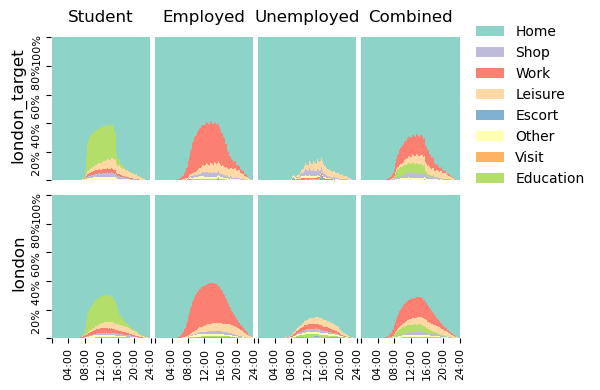

In [23]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {
        "london_target": training_schedules["london"],
        "london": schedules["london"],
    },
    {
        "london_target": training_attributes["london"],
        "london": attributes["london"],
    },
    by="employment",
    filter=["student", "employed", "unemployed"],
)

Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']
Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']


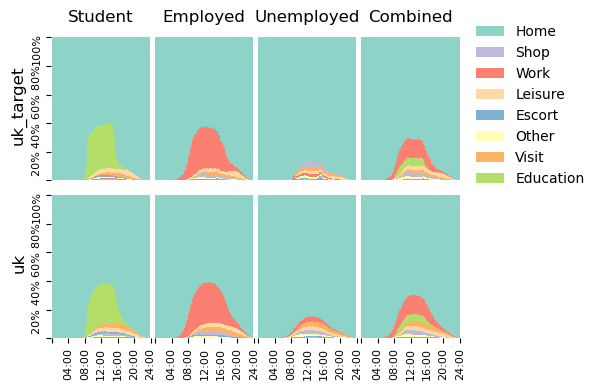

In [24]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {"uk_target": training_schedules["uk"], "uk": schedules["uk"]},
    {"uk_target": training_attributes["uk"], "uk": attributes["uk"]},
    by="employment",
    filter=["student", "employed", "unemployed"],
)

Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']
Split schedules into 6 groups by employment: ['employed', 'retired', 'student', 'unemployed', 'unknown', 'void']


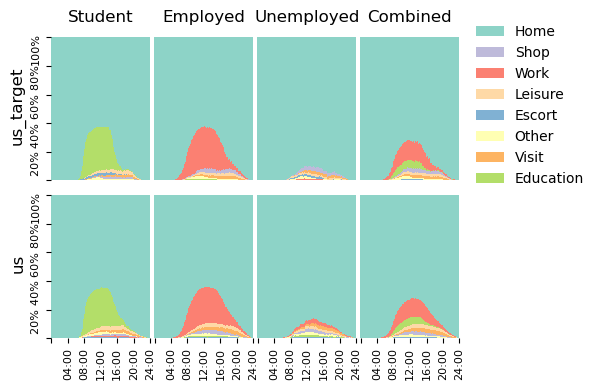

In [25]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {"us_target": training_schedules["us"], "us": schedules["us"]},
    {"us_target": training_attributes["us"], "us": attributes["us"]},
    by="employment",
    filter=["student", "employed", "unemployed"],
)

Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']
Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']


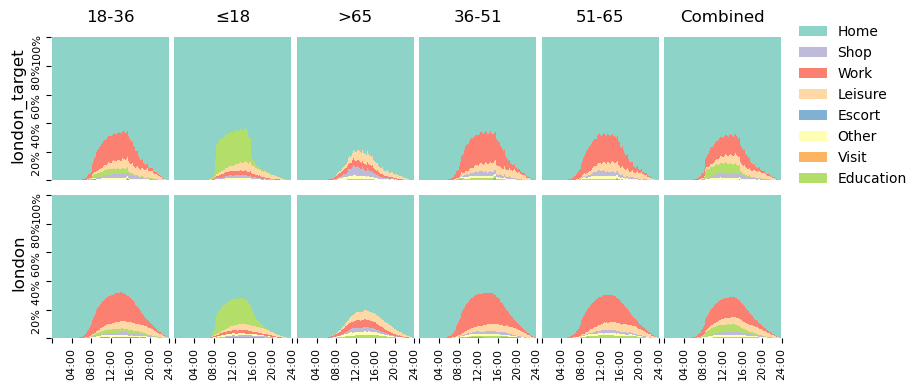

In [26]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {
        "london_target": training_schedules["london"],
        "london": schedules["london"],
    },
    {
        "london_target": training_attributes["london"],
        "london": attributes["london"],
    },
    by="age",
)

Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']
Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']


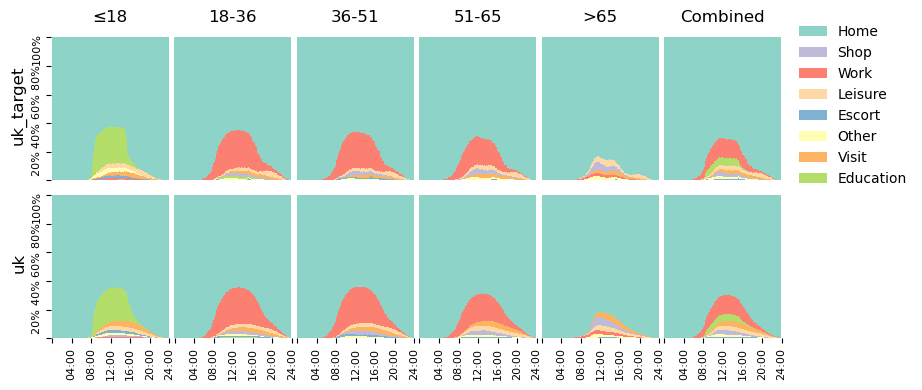

In [30]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {"uk_target": training_schedules["uk"], "uk": schedules["uk"]},
    {"uk_target": training_attributes["uk"], "uk": attributes["uk"]},
    by="age",
    filter=["≤18", "18-36", "36-51", "51-65", ">65"],
)

Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']
Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']


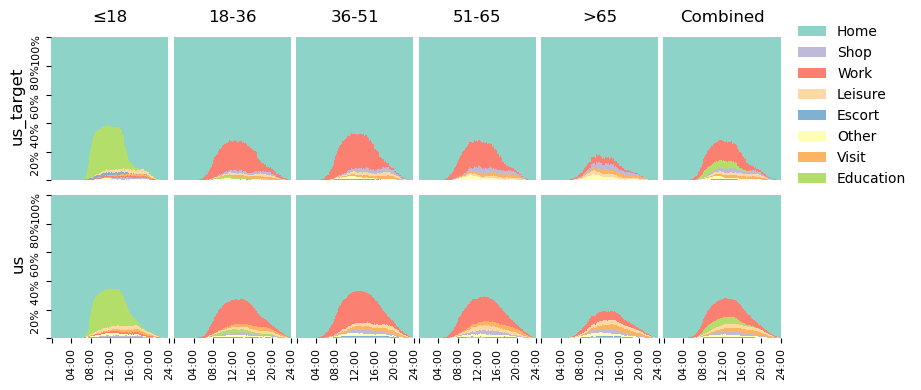

In [31]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {"us_target": training_schedules["us"], "us": schedules["us"]},
    {"us_target": training_attributes["us"], "us": attributes["us"]},
    by="age",
    filter=["≤18", "18-36", "36-51", "51-65", ">65"],
)

Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']
Split schedules into 5 groups by age: ['18-36', '36-51', '51-65', '>65', '≤18']


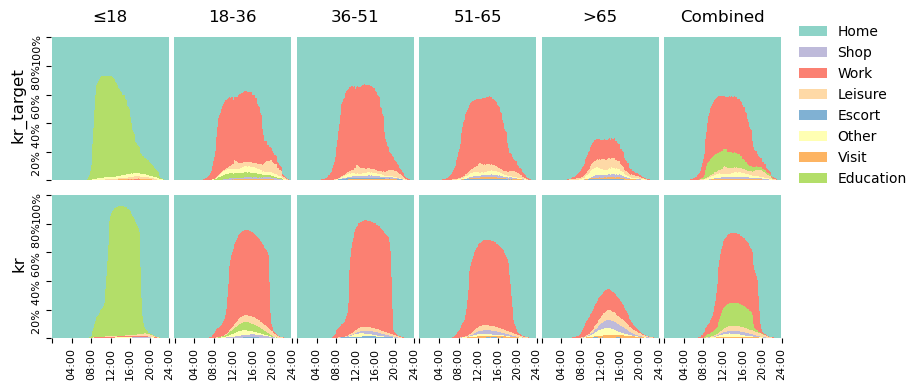

In [32]:
freq_plotter(
    training_schedules["training"],
    training_attributes["training"],
    {"kr_target": training_schedules["kr"], "kr": schedules["kr"]},
    {"kr_target": training_attributes["kr"], "kr": attributes["kr"]},
    by="age",
    filter=["≤18", "18-36", "36-51", "51-65", ">65"],
)

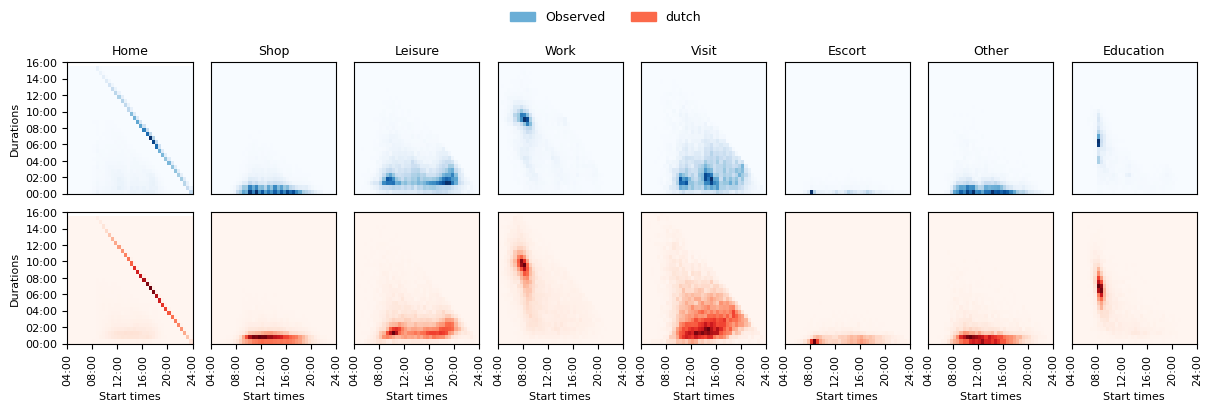

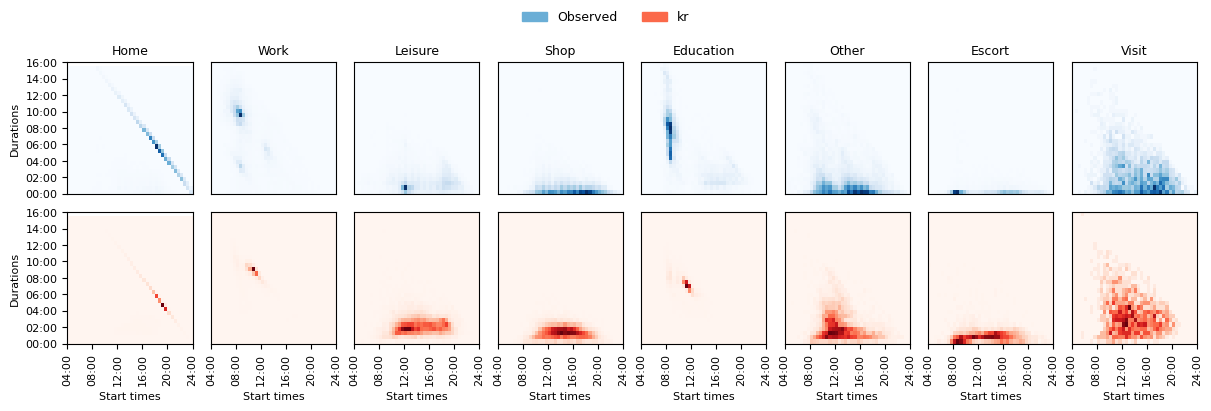

In [38]:
f = joint_time_distributions_plot(
    observed=training_schedules["dutch"],
    ys={"dutch": schedules["dutch"]},
    cmap=cmap,
    figsize=(12, 4),
)

f = joint_time_distributions_plot(
    observed=training_schedules["kr"],
    ys={"kr": schedules["kr"]},
    cmap=cmap,
    figsize=(12, 4),
)
# f = frequency_plots(
#     observed=target, ys=training_schedules, cmap=cmap, figsize=(12, 6)
# )
# f = sequence_prob_plot(
#     observed=target, ys=training_schedules, cmap=cmap, figsize=(12, 6)
# )

In [ ]:
# training_attributes = {
#     "uk": pd.read_csv(training_data_route / "uk_attributes.csv"),
#     "uk+aus": pd.read_csv(training_data_route / "uk+aus_attributes.csv"),
#     "western": pd.read_csv(training_data_route / "west_attributes.csv"),
#     "world": pd.read_csv(training_data_route / "world_attributes.csv"),
# }

# training_schedules = {
#     "uk": pd.read_csv(training_data_route / "uk_activities.csv"),
#     "uk+aus": pd.read_csv(training_data_route / "uk+aus_activities.csv"),
#     "western": pd.read_csv(training_data_route / "west_activities.csv"),
#     "world": pd.read_csv(training_data_route / "world_activities.csv"),
# }

In [ ]:
counter = {}
# load each and get counts per source
counter["baseline"] = target_attributes.source.value_counts()
for name, data in training_attributes.items():
    print(data.source.unique())
    counter[name] = data.source.value_counts()
df = pd.DataFrame(counter)


order = ["ktdb", "ltds", "vista", "qhts", "nhts", "nts"]
df = df.loc[order].fillna(0)
totals = df.sum()
totals_row = pd.DataFrame([totals], index=["Total"])
df = pd.concat([df, totals_row])
print(df.to_latex(float_format="{:.0f}".format))

In [ ]:
def distance_table(batch_path, suffix=""):
    df = pd.read_csv(batch_path / f"domain_distances{suffix}.csv").set_index(
        "domain"
    )
    order = [
        "participations",
        "transitions",
        "timing",
        "feasibility",
        "creativity",
    ]
    print(df.loc[order].to_latex(float_format="{:.3f}".format))
    return df.loc[order]


df = distance_table(Path("../../logs/foundations/B"), suffix="")

df

In [ ]:
df_alt = distance_table(Path("../../logs/foundations/B_alt"), suffix="")
diff = 100 * (df - df_alt) / df_alt
order = ["participations", "transitions", "timing", "feasibility", "creativity"]
print(diff.loc[order].to_latex(float_format="{:.1f}\%".format))
diff

In [ ]:
# _ = plot_b(
#     training_schedules, training_attributes, target_schedules, target_attributes
# )

In [ ]:
batch_root = Path("../../logs/foundations/B")

batch_paths = {
    "B0 (baseline)": batch_root / "baseline",
    "B1 (UK)": batch_root / "uk",
    "B2 (UK+AUS)": batch_root / "uk+aus",
    "B3 (West)": batch_root / "west",
    "B4 (World)": batch_root / "world",
}

# find data
data_root = Path("../../tmp/foundation")
target_schedules = pd.read_csv(
    data_root / "experiment_b" / "nts_activities_2024.csv"
)
acts = list(target_schedules.act.value_counts(ascending=False).index)
class_map = {n: i for i, n in enumerate(acts)}

target_attributes = pd.read_csv(
    data_root / "experiment_b" / "nts_attributes_2024.csv"
)

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=target_attributes)
    for n, p in batch_paths.items()
}
print(schedules.keys())
print(attributes.keys())

In [ ]:
_ = plot_b(schedules, attributes, target_schedules, target_attributes)